# 이진 로지스틱 회귀

## 분류 대상과 입력

- 이진 로지스틱 회귀(binary logistic regression)는 두 클래스 중 하나의 확률을 추정하는 분류 모델이다. 이름에 ‘회귀’가 있지만 예측 대상은 클래스이다.
- 메시지를 정상($y=0$) 또는 스팸($y=1$)으로 분류하며, 탐지 대상인 스팸을 양성 클래스(positive class)로 둔다.
- 입력 특징(feature)은 홍보 문구 수 $x_1$과 링크 수 $x_2$이다. 학습 후 완전히 분리되도록 두 합성 집단 사이에 의도적으로 간격을 둔다.

## 점수–확률–클래스 대응

### 선형 점수

- 두 입력의 가중합과 절편으로 선형 점수(linear score) $z$를 계산한다.

  $\displaystyle z=b+w_1x_1+w_2x_2.$

- 절편(intercept) $b$는 두 입력이 모두 0일 때의 점수이다. 가중치(weight) $w_1,w_2$는 각 입력의 기여를 정한다.
- 학습으로 $b,w_1,w_2$를 정한다. $z$는 음수나 양수가 될 수 있으며 확률과 구별된다.

### 시그모이드 확률

- 시그모이드 함수(sigmoid function)는 $z$를 모델이 추정한 스팸 확률 $p$로 바꾼다.

  $\displaystyle p=P(y=1\mid\mathbf{x})=\sigma(z)=\frac{1}{1+e^{-z}}.$

- $e$는 자연지수의 밑이다. $z$가 커지면 $p$가 커지며, $z=0$이면 $p=0.5$이다. 정상일 확률은 $1-p$이다.

  <img src="https://raw.githubusercontent.com/sonamu-jun/introduction-to-ai-convergence/main/07-1_Classification/assets/02_sigmoid_and_threshold.png" alt="시그모이드와 분류 임곗값" width="512" style="max-width:100%;height:auto;">

### 분류 임곗값

- 임곗값(threshold) $\tau$ 이상이면 스팸, 그보다 작으면 정상으로 예측한다.

  $\displaystyle \hat y=\begin{cases}1\;\text{(Spam)},&p\ge\tau,\\0\;\text{(Legitimate)},&p<\tau.\end{cases}$

- $\tau=0.5$의 결정 경계(decision boundary)는 $b+w_1x_1+w_2x_2=0$이다. 이 경계는 두 입력으로 이루어진 평면에서 직선이다.


## 손실과 매개변수 학습

### 교차 엔트로피

- 이진 교차 엔트로피(binary cross-entropy)는 실제 클래스에 부여한 확률로 메시지 하나의 손실을 계산한다.

  $\displaystyle \ell(y,p)=-\big[y\log p+(1-y)\log(1-p)\big].$

- 스팸에는 $-\log p$, 정상에는 $-\log(1-p)$가 적용된다. 자연로그를 사용하며, 실제 클래스의 확률이 낮을수록 손실이 커진다.
- 학습 손실(training loss) $L$은 학습 메시지 전체의 평균 손실이다.

### 경사하강법

- 경사하강법(gradient descent)은 손실의 기울기(gradient)와 반대 방향으로 매개변수를 갱신한다.

  $\displaystyle \theta\leftarrow\theta-\eta\,\frac{\partial L}{\partial\theta}.$

- $\theta$는 절편 또는 가중치, $\partial L/\partial\theta$는 그 값에 따른 손실의 변화율이다. 학습률(learning rate) $\eta$가 갱신 크기를 조절하며, 너무 크면 손실이 증가할 수 있다.
- 입력은 학습 데이터의 평균과 표준편차로 표준화(standardization)한다. 화면에는 원래 개수 단위로 환산한 계수를 반올림해 표시한다.

## 학습 단계와 입력 변화

### 학습에 따른 점수 변화

- ‘Iteration’은 실제 계수 갱신을 선택하고 ‘Fit model’은 600회 결과를 적용한다. 이 예제는 학습 후 기본 임곗값 0.5에서 두 클래스가 완전히 분리된다.
- 점의 좌표 $(z,\sigma(z))$는 점수와 스팸 확률이고, 색은 실제 클래스이다. 같은 점수의 메시지는 겹친다.
- 곡선·축·입력 데이터는 고정한다. 학습이 진행되면 정상은 왼쪽 아래로, 스팸은 오른쪽 위로 분리된다.

### 입력 조절과 임곗값

- ‘Decision variable x1’은 홍보 문구 수, ‘Decision variable x2’는 링크 수이다. 새 메시지의 입력을 바꾸며, 학습한 계수는 그대로 둔다.
- 가로 점선은 확률 임곗값이고, 세로 점선은 이에 대응하는 점수 경계이다. 임곗값은 예측 클래스만 바꾸며 점수·확률·학습 손실은 바꾸지 않는다.
- 검증 정확도(validation accuracy)는 계수 학습에 쓰지 않은 메시지 중 올바르게 분류한 비율이다.


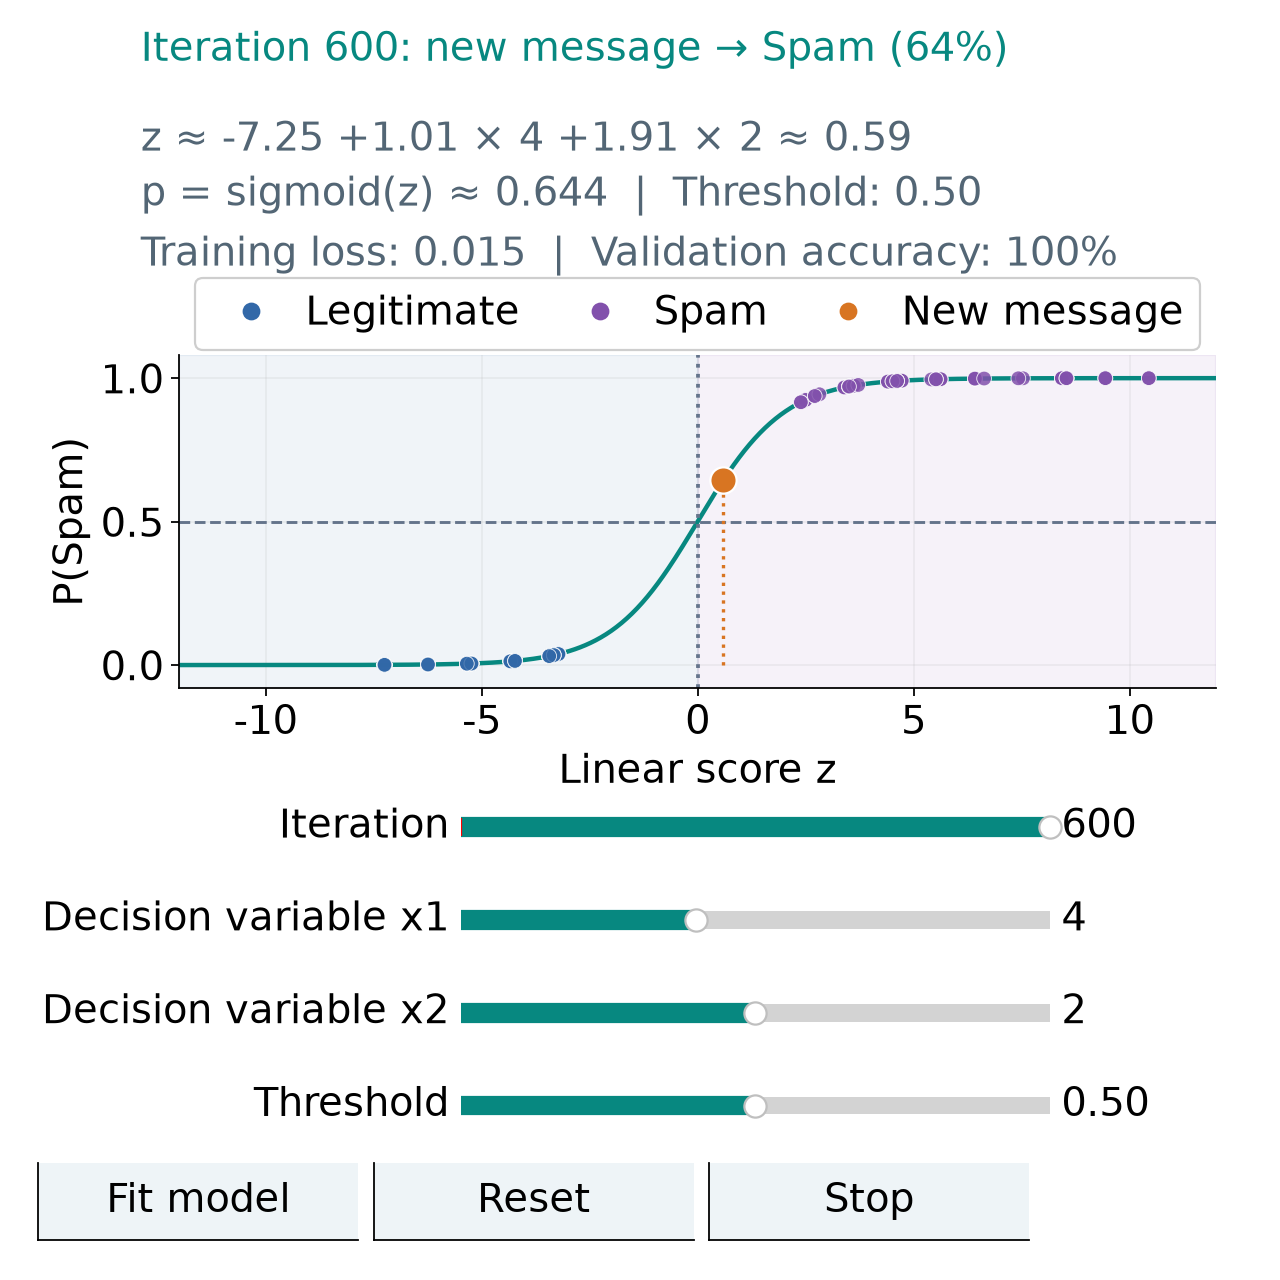

In [1]:
import os
import sys
import io
import numpy as np
import matplotlib

CLASSIFICATION_STATIC = os.environ.get("CLASSIFICATION_STATIC") == "1"
CLASSIFICATION_BROWSER = sys.platform == "emscripten"
if not CLASSIFICATION_STATIC and not CLASSIFICATION_BROWSER:
    from IPython import get_ipython
    shell = get_ipython()
    if shell is not None and getattr(shell, "kernel", None) is not None:
        shell.run_line_magic("matplotlib", "widget")

import matplotlib.pyplot as plt
from matplotlib.widgets import Slider, Button
from matplotlib.colors import ListedColormap
from IPython.display import Image, display
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

plt.rcParams.update({
    "font.size": 18, "axes.labelsize": 18,
    "xtick.labelsize": 18, "ytick.labelsize": 18, "legend.fontsize": 18,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .16, "lines.linewidth": 2.5,
    "axes.unicode_minus": False, "figure.facecolor": "white",
})
BLUE, TEAL, ORANGE, PURPLE = "#3268a8", "#078880", "#d87522", "#8251ac"


def sigmoid(score):
    score = np.clip(np.asarray(score, dtype=float), -500, 500)
    return 1 / (1 + np.exp(-score))


def softmax(scores):
    scores = np.asarray(scores, dtype=float)
    weights = np.exp(scores - scores.max(axis=-1, keepdims=True))
    return weights / weights.sum(axis=-1, keepdims=True)


def binary_loss(labels, scores):
    return float(np.mean(np.logaddexp(0, scores) - labels * scores))


def classification_metrics(observed, predicted):
    observed, predicted = np.asarray(observed), np.asarray(predicted)
    tp = int(np.sum((observed == 1) & (predicted == 1)))
    tn = int(np.sum((observed == 0) & (predicted == 0)))
    fp = int(np.sum((observed == 0) & (predicted == 1)))
    fn = int(np.sum((observed == 1) & (predicted == 0)))
    return {"TP": tp, "TN": tn, "FP": fp, "FN": fn,
            "accuracy": (tp + tn) / len(observed),
            "precision": tp / (tp + fp) if tp + fp else np.nan,
            "recall": tp / (tp + fn) if tp + fn else np.nan,
            "F1": 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else np.nan}


def percent(value):
    return "undefined" if not np.isfinite(value) else f"{value:.0%}"


for _previous_view in globals().get("_classification_views", {}).values():
    _previous_view.close()
_classification_views = {}


class ClassificationExplorer:

    def __init__(self, name, render, sliders, actions=()):
        self.render = render
        self.slider_specs = sliders
        self.controls, self.buttons, self.state = {}, {}, {}
        self.stopped = False
        self.defaults = {key: initial for key, label, low, high, initial, step, fmt in sliders}
        with plt.ioff():
            height = min(8.0, 6.8 + .58 * len(sliders))
            self.figure = plt.figure(figsize=(8, height), dpi=64)
        self.status = self.figure.text(.11, 1 - .38 / height, "", fontsize=18, color=TEAL)
        self.detail = self.figure.text(.11, 1 - .66 / height, "", va="top", fontsize=18, color="#536675", linespacing=1.5)
        bottom = (1.38 + .58 * len(sliders)) / height
        top = 1 - 2.22 / height
        self.ax = self.figure.add_axes([.14, bottom, .81, top - bottom])
        for i, (key, label, low, high, initial, step, fmt) in enumerate(sliders):
            y = (.98 + .58 * (len(sliders) - i - 1)) / height
            slider = Slider(self.figure.add_axes([.36, y, .46, .22 / height]),
                            label, low, high, valinit=initial, valstep=step,
                            valfmt=fmt, color=TEAL)
            slider.label.set_fontsize(18)
            slider.valtext.set_fontsize(18)
            slider.on_changed(self.update)
            self.controls[key] = slider
        commands = list(actions) + [("Reset", lambda view: view.reset()),
                                    ("Stop", lambda view: view.stop())]
        self.commands = commands
        width = min(.25, .94 / len(commands) - .012)
        for i, (label, callback) in enumerate(commands):
            button = Button(self.figure.add_axes([.03 + i * (width + .012), .25 / height, width, .48 / height]),
                            label,
                            color="#eef4f7", hovercolor="#d7e9e6")
            button.label.set_fontsize(18)
            button.on_clicked(lambda event, cb=callback: cb(self) if not self.stopped else None)
            self.buttons[label] = button
        self.figure.canvas.mpl_connect("close_event", lambda event: self.stop())
        _classification_views[name] = self
        self.update()

    def update(self, _=None):
        if self.stopped:
            return
        self.ax.clear()
        self.state = self.render(self, **{key: slider.val for key, slider in self.controls.items()})
        self.figure.canvas.draw_idle()
        self.refresh_local()

    def set_values(self, **values):
        if self.stopped:
            return
        for key, value in values.items():
            slider = self.controls[key]
            events, drawing = slider.eventson, slider.drawon
            slider.eventson = slider.drawon = False
            slider.set_val(value)
            slider.eventson, slider.drawon = events, drawing
        self.update()

    def reset(self):
        self.set_values(**self.defaults)

    def refresh_local(self):
        if not hasattr(self, "local_image"):
            return
        from matplotlib.transforms import Bbox
        width, height = self.figure.get_size_inches()
        lower = ((self.tree_ax.get_position().y0 - .02) * height
                 if hasattr(self, "tree_ax") else max(0, self.ax.get_position().y0 * height - .78))
        buffer = io.BytesIO()
        self.figure.savefig(buffer, format="png", dpi=64, facecolor="white",
                            bbox_inches=Bbox.from_extents(0, lower, width, height))
        self.local_image.value = buffer.getvalue()
        self.syncing_local = True
        for key, control in self.local_controls.items():
            control.value = self.controls[key].val
        self.syncing_local = False

    def start_local(self):
        from ipywidgets import Image as WidgetImage, FloatSlider, IntSlider
        from ipywidgets import Button as WidgetButton, HBox, VBox, Layout
        self.syncing_local = False
        self.local_image = WidgetImage(format="png", layout=Layout(
            width="100%", max_width="512px", height="auto"))
        self.local_controls, self.local_buttons = {}, {}
        for key, label, low, high, initial, step, fmt in self.slider_specs:
            slider_type = IntSlider if fmt == "%0.0f" and step == 1 else FloatSlider
            control = slider_type(value=initial, min=low, max=high, step=step,
                                  description=label, readout_format=fmt.replace("%0", ""),
                                  continuous_update=True,
                                  style={"description_width": "180px"},
                                  layout=Layout(width="100%", max_width="512px"))
            def changed(change, key=key):
                if not self.syncing_local and not self.stopped:
                    self.controls[key].set_val(change["new"])
            control.observe(changed, names="value")
            self.local_controls[key] = control
        for label, callback in self.commands:
            button = WidgetButton(description=label, layout=Layout(
                flex="1 1 0", min_width="120px", height="34px", margin="2px"))
            button.on_click(lambda _, cb=callback: cb(self) if not self.stopped else None)
            self.local_buttons[label] = button
        row = HBox(list(self.local_buttons.values()), layout=Layout(width="100%", flex_flow="row wrap"))
        self.local_row = row
        self.local_output = VBox([self.local_image, *self.local_controls.values(), row],
                                layout=Layout(width="100%", max_width="512px"))
        self.refresh_local()
        display(self.local_output)

    def start(self):
        if CLASSIFICATION_STATIC:
            buffer = io.BytesIO()
            self.figure.savefig(buffer, format="png", dpi=160, facecolor="white")
            display(Image(data=buffer.getvalue(), width=512,
                          alt=self.status.get_text() + ". " + self.detail.get_text()))
            plt.close(self.figure)
        elif CLASSIFICATION_BROWSER:
            plt.show(block=False)
        elif hasattr(self.figure.canvas, "toolbar_visible"):
            self.start_local()
        else:
            plt.show(block=False)

    def stop(self):
        if self.stopped:
            return
        self.stopped = True
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.set_active(False)
        for control in [*getattr(self, "local_controls", {}).values(),
                        *getattr(self, "local_buttons", {}).values()]:
            control.disabled = True
        if hasattr(self, "local_buttons"):
            self.local_buttons["Stop"].description = "Stopped"
        self.buttons["Stop"].label.set_text("Stopped")
        self.figure.canvas.draw_idle()

    def close(self):
        self.stop()
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.disconnect_events()
        plt.close(self.figure)
        if hasattr(self, "local_output"):
            self.local_output.close()
            self.local_image.close()
            self.local_row.close()
            for control in [*self.local_controls.values(), *self.local_buttons.values()]:
                control.close()


def make_messages(seed, count=240, spam_fraction=.35):
    rng = np.random.default_rng(seed)
    labels = np.zeros(count, dtype=int)
    labels[:round(count * spam_fraction)] = 1
    rng.shuffle(labels)
    phrases = rng.binomial(10, np.where(labels == 1, .53, .13))
    links = rng.binomial(4, np.where(labels == 1, .57, .13))
    return np.column_stack([phrases, links]), labels


def make_fruit(seed):
    rng = np.random.default_rng(seed)
    labels = np.repeat(np.arange(3), 60)
    centers = np.array([[8, 1.15], [30, 1.05], [53, 2.8]])
    spreads = np.array([[8, .18], [7, .16], [7, .5]])
    values = centers[labels] + rng.normal(size=(len(labels), 2)) * spreads[labels]
    return np.clip(values, [0, .7], [70, 4.2]), labels

rng = np.random.default_rng(70)
feature_grid = np.array([(phrases, links) for phrases in range(11) for links in range(5)])
construction_score = feature_grid[:, 0] + 2 * feature_grid[:, 1]
labels = np.zeros(240, dtype=int)
labels[:84] = 1
rng.shuffle(labels)
messages = np.empty((len(labels), 2), dtype=int)
for label, pool in [(0, feature_grid[construction_score <= 4]),
                    (1, feature_grid[construction_score >= 10])]:
    selected = labels == label
    messages[selected] = pool[rng.integers(len(pool), size=selected.sum())]
train_id, validation_id = train_test_split(np.arange(len(labels)), test_size=.3,
                                         stratify=labels, random_state=70)
feature_mean = messages[train_id].mean(axis=0)
feature_scale = messages[train_id].std(axis=0)


def message_features(values):
    values = np.atleast_2d(values)
    return np.column_stack([np.ones(len(values)), (values - feature_mean) / feature_scale])


def raw_coefficients(beta):
    weights = beta[1:] / feature_scale
    return np.r_[beta[0] - feature_mean @ weights, weights]


train_features = message_features(messages[train_id])
coefficients = np.array([0., 1., -1.])
coefficient_history = [coefficients.copy()]
for iteration in range(600):
    probability = sigmoid(train_features @ coefficients)
    gradient = train_features.T @ (probability - labels[train_id]) / len(train_id)
    coefficients -= .15 * gradient
    coefficient_history.append(coefficients.copy())
coefficient_history = np.asarray(coefficient_history)
all_query_scores = message_features(feature_grid) @ coefficient_history.T
score_limit = float(np.ceil(np.abs(all_query_scores).max()) + 1)
score_grid = np.linspace(-score_limit, score_limit, 601)


def render_binary(view, iteration, phrases, links, threshold):
    beta = coefficient_history[int(iteration)]
    raw = raw_coefficients(beta)
    query = np.array([[phrases, links]])
    score = float((message_features(query) @ beta)[0])
    probability = float(sigmoid(score))
    train_scores = train_features @ beta
    train_probability = sigmoid(train_scores)
    validation_probability = sigmoid(message_features(messages[validation_id]) @ beta)
    predicted = (validation_probability >= threshold).astype(int)
    result = classification_metrics(labels[validation_id], predicted)
    loss = binary_loss(labels[train_id], train_scores)
    ax = view.ax
    boundary = float(np.log(threshold / (1 - threshold)))
    ax.axvspan(-score_limit, boundary, color=BLUE, alpha=.07)
    ax.axvspan(boundary, score_limit, color=PURPLE, alpha=.07)
    ax.plot(score_grid, sigmoid(score_grid), color=TEAL, linewidth=2, zorder=2)
    colors = np.where(labels[train_id] == 0, BLUE, PURPLE)
    ax.scatter(train_scores, train_probability, s=44, c=colors,
               alpha=.85, edgecolors="white", linewidths=.4, zorder=3)
    ax.axvline(boundary, color="#64748b", linestyle=":", linewidth=1.7)
    ax.axhline(threshold, color="#64748b", linestyle="--", linewidth=1.3)
    ax.plot([score, score], [0, probability], ":", color=ORANGE, linewidth=1.5)
    ax.scatter([score], [probability], s=140, color=ORANGE, edgecolor="white", zorder=5)
    from matplotlib.lines import Line2D
    handles = [Line2D([], [], linestyle="", marker="o", color=color,
                      markersize=7, label=label)
               for color, label in [(BLUE, "Legitimate"), (PURPLE, "Spam"),
                                    (ORANGE, "New message")]]
    ax.legend(handles=handles, loc="lower center", bbox_to_anchor=(.5, 1.015),
              ncol=3, fontsize=18, framealpha=.95, borderaxespad=0,
              handletextpad=.35, columnspacing=1.)
    ax.set(xlim=(-score_limit, score_limit), ylim=(-.08, 1.08),
           xlabel="Linear score z", ylabel="P(Spam)", yticks=[0, .5, 1])
    label = "Spam" if probability >= threshold else "Legitimate"
    view.status.set_text(f"Iteration {int(iteration)}: new message → {label} ({probability:.0%})")
    view.detail.set_text(
        f"z ≈ {raw[0]:.2f} {raw[1]:+.2f} × {phrases:.0f} {raw[2]:+.2f} × {links:.0f} ≈ {score:.2f}\n"
        f"p = sigmoid(z) ≈ {probability:.3f}  |  Threshold: {threshold:.2f}\n"
        f"Training loss: {loss:.3f}  |  Validation accuracy: {result['accuracy']:.0%}")
    return {"probability": probability, "label": label, "score": score, "query": query,
            "boundary": boundary,
            "train_probability": train_probability, "score_limit": score_limit,
            "coefficients": beta.copy(), "raw_coefficients": raw,
            "train_scores": train_scores, "validation_probability": validation_probability,
            "prediction": predicted, "metrics": result, "loss": loss}


binary_demo = ClassificationExplorer("binary", render_binary, [
    ("iteration", "Iteration", 0, 600, 0, 1, "%0.0f"),
    ("phrases", "Decision variable x1", 0, 10, 4, 1, "%0.0f"),
    ("links", "Decision variable x2", 0, 4, 2, 1, "%0.0f"),
    ("threshold", "Threshold", .05, .95, .5, .05, "%0.2f"),
], actions=[("Fit model", lambda view: view.set_values(iteration=600))])
if CLASSIFICATION_STATIC:
    binary_demo.set_values(iteration=600)
binary_demo.start()


## 특징과 선형 경계의 한계

- 실제 정상 메시지에도 홍보 문구와 링크가 있을 수 있다. 두 개수만으로 발신자·의미·맥락을 구분할 수는 없다.
- 선형 경계로 구분하기 어려운 클래스 배치도 있다. 임곗값을 낮추면 스팸을 더 잡을 수 있지만 정상 메시지를 차단하는 오탐도 늘 수 있다.
- 검증 데이터(validation data)로 설정을 선택한 뒤, 별도 시험 데이터(test data)로 최종 성능을 평가한다.
